### YOLOv8

Das fertige NHCW-Array kann nun YOLO übergeben werden.

Das Ergebnis wird von dem Ausgabe-Layer gelesen. YOLOv8 liefert ein Array in dem Format (N, 84, 8400) zurück. N steht für die Anzahl an Bildern.

Auf der 2. Achse liefert YOLO 84-Attribute zu einer Erkennung zurück.
Diese sind [central-x, central-y, width, height, detection score für die 80-Coco Klassen].
Auf der 3. Achse sind die Detections. Das Array muss daher zuerst transponiert werden, sodass die Detections vor den Attributen dazu stehen.

YOLO liefer außerdem immer 8400 Erkennungen zurück. Dafür liegt der Confidence-Score, also wie sicher das Model sich ist, bei den meisten Coco-Klassen deutlich unter 50%


In [ ]:
import numpy as np
import cv2 as cv

from yolo.utils.letterbox import letterbox

image: np.ndarray = cv.imread('pictures/bicycle.jpg')
resized, transform = letterbox(image)
blob = cv.dnn.blobFromImage(
    image=resized, scalefactor=1 / 255, size=(640, 640),
    swapRB=True, crop=False
)

# Load YOLO
net = cv.dnn.readNet('models/yolov8n.onnx')

# Put the blob into the input layer and receive the result from the output layer.
net.setInput(blob)
result = net.forward(net.getUnconnectedOutLayersNames())[0]
print(f"Output shape: {result.shape}")

# Transpose the 2 axis
result = np.transpose(result[0])
print(f"Transformed shape: {result.shape}")


#### Verarbeiten der Erkennungen
Nachdem die Ausgabe von YOLO da ist, muss diese verarbeitet werden.
Wichtig sind die Informationen Class-Id (Was wurde erkannt?), Confidence (Wie sicher ist YOLO sich?) und die Box-Koordinate mit Höhe und Breite


In [6]:
# Get the coco classes as 2d nparray and find the highest confidences
scores = result[:, 4:]
confidences = np.max(scores, axis=1)
class_ids = np.argmax(scores, axis=1)

# Filter detections above the threshold
mask = confidences > 0.5
print(f"{mask.sum()} valid detections (No NMS)")


boxes = result[mask, :4]
confidences = confidences[mask]
class_ids = class_ids[mask]


#### Resizing
Da YOLO die Erkennung auf einem 640x640 Frame gemacht hat, beziehen sich auch die Box-Koordinaten auf diese Skalierung. Damit die Koordinaten wieder zum ursprünglichen Bild passen, müssen die Koordinaten daher auch wieder hochskaliert werden.


In [14]:
# The transform variable is from the letterbox function() in the top section and gives information about how the frame was rescaled.
# We can use this to scale back.

x, y = boxes[:, 0], boxes[:, 1]
w, h = boxes[:, 2], boxes[:, 3]

left = ((x - w / 2) - transform.pad_x) / transform.scale
top = ((y - h / 2) - transform.pad_y) / transform.scale
width = w / transform.scale
height = h / transform.scale

resized_boxes = np.column_stack([left, top, width, height]).astype(int)

#### Non-Maximum-Suppression (NMS)

YOLO gibt mehrere Detections für dasselbe Objekt zurück, mit ein wenig unterschiedlichen Box-Koordinaten. Damit es keine überlappenden Boxen auf einem Objekt gibt, wird die Non-Maximum-Suppression Technik angewendet.

Die NMS-funktion von OpenCV braucht zudem die Boxen in dem Format [left, top, width, height]. Daher muss die Ausgabe zuvor noch angepasst werden.
Zum Zeichnen braucht OpenCV außerdem 2 Koordinaten an den Ecken der Box. Daher wird hier Punkt1 und Punkt2 erzeugt.


In [15]:
# Take the boxes with the highest coverage
indices = cv.dnn.NMSBoxes(
    bboxes=resized_boxes, scores=confidences,
    score_threshold=0.5, nms_threshold=0.45
)

indices = np.array(indices)

left = boxes[indices, 0]
top = boxes[indices, 1]
width = boxes[indices, 2]
height = boxes[indices, 3]

boxes = np.column_stack([left, top, left+width, top+height])
confidences = confidences[indices]
class_ids = class_ids[indices]

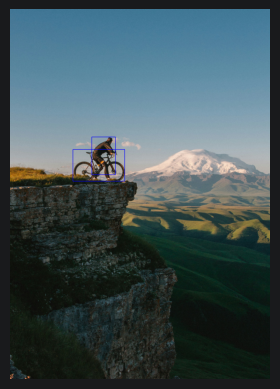

In [16]:
import matplotlib.pyplot as plt

# Draw

for box in boxes:
    cv.rectangle(img=image, pt1=box[0], pt2=box[1], color=(255, 0, 0), thickness=3)

# Transform BGR to RGB for matplotlib
canvas_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
plt.imshow(canvas_rgb)
plt.axis("off")
plt.show()
